# Лабораторная работа № 8.  Построение автокодировщиков

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

make_moons(noise=0.06) 

Доп.
зашумлённых
признаков
Итоговая
размерность входа
Латентная
размерность
Уровень
шума DAE
(σ)


## Данные и подготовка выборки

Используется вариант 13: `make_moons(n_samples=600, noise=0.06)` с двумя исходными координатами и четырьмя дополнительными признаками. Каждый дополнительный признак получен как линейная комбинация двух исходных координат со случайными коэффициентами от 0.5 до 1.0 и гауссовым шумом со стандартным отклонением 0.08. Итоговая размерность входа — **6 признаков**. Данные случайно делятся в соотношении **80/20**: 480 обучающих и 120 тестовых объектов. Стандартизатор обучается только на обучающей части, а затем применяется к тестовой, что исключает утечку информации. Стандартизация выравнивает масштабы признаков, чтобы они сопоставимо влияли на MSE.

In [1]:
import numpy as np
import torch
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
import matplotlib.pyplot as plt

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
torch.manual_seed(42)
np.random.seed(42)

In [3]:
N_SAMPLES = 600
N_EXTRA = 4

In [4]:
X2, y = make_moons(n_samples=N_SAMPLES, noise=0.06, random_state=42)

coeffs1 = np.random.uniform(0.5, 1.0, size=(1, N_EXTRA))
coeffs2 = np.random.uniform(0.5, 1.0, size=(1, N_EXTRA))
extra = (0.08 * np.random.randn(N_SAMPLES, N_EXTRA)) + coeffs1 * X2[:, [0]] + coeffs2 * X2[:, [1]]

X = np.hstack([X2, extra]).astype(np.float32)
n_features = X.shape[1]

In [5]:
X2.shape

(600, 2)

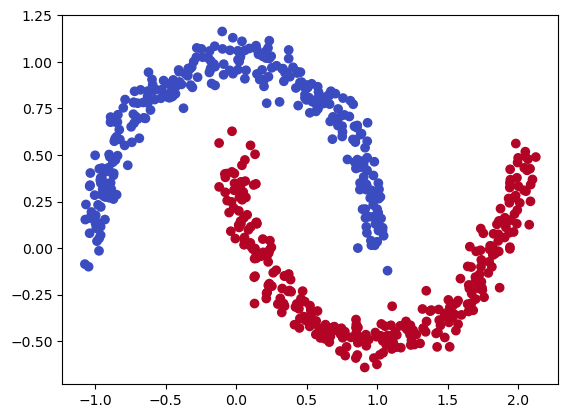

In [6]:
plt.scatter(X2[:, 0], X2[:, 1], c=y, cmap='coolwarm')

In [7]:
idx = np.random.permutation(N_SAMPLES)
n_train = round(N_SAMPLES * 0.8)
train_idx, test_idx = idx[:n_train], idx[n_train:]
X_train, X_test = X[train_idx], X[test_idx]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)
X_scaled = scaler.transform(X).astype(np.float32)

X_train_t, X_test_t = torch.tensor(X_train, dtype=torch.float32), torch.tensor(X_test, dtype=torch.float32)


## Архитектура автокодировщика

**Энкодер:** `6 → 32 → ReLU → 2`. **Декодер:** `2 → 32 → ReLU → 6`. Латентный слой размерности **2** соответствует варианту 13 и позволяет визуализировать сжатые объекты на плоскости. Нелинейность ReLU помогает моделировать изогнутую структуру `make_moons`, а линейный выход декодера подходит для стандартизированных признаков, не ограниченных интервалом [0, 1]. Декодер восстанавливает исходные шесть признаков; функция потерь — среднеквадратичная ошибка (MSE), оптимизатор — Adam.

In [8]:
class AE(nn.Module):
    def __init__(self, n_in, n_latent, hidden=32):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Linear(n_in, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_latent)
        )
        self.dec = nn.Sequential(
            nn.Linear(n_latent, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_in)
        )
    
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z

In [9]:
N_LATENT = 2
ae = AE(n_features, N_LATENT)
opt = torch.optim.Adam(params=ae.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

### Схема сети

Следующая ячейка визуализирует архитектуру через `torchview`. Для её выполнения нужны библиотека `torchview` и Graphviz. Если они не установлены, установите зависимости в используемом окружении; сама модель и обучение от этой визуализации не зависят.


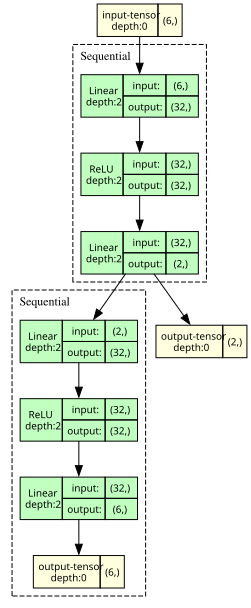

In [10]:
from torchview import draw_graph

model_graph = draw_graph(
    ae,
    input_size=((n_features,)), 
    graph_name="AutoEncoder",
    expand_nested=True
)
model_graph.visual_graph

## Общая функция обучения

Функция `train` получает модель, оптимизатор, обучающие входы, **целевые** объекты, число эпох и функцию потерь. Для обычного AE входы и цели совпадают; для DAE входы зашумлены, но целью остаются чистые объекты. Функция возвращает историю MSE по эпохам и одинаково применяется в основном и дополнительном заданиях.

In [11]:
def train(model, optimizer, X_input, X_target, epochs, criterion):
    loss_hist = []
    model.train()
    for _ in range(epochs):
        x_pred, _ = model(X_input)
        loss = criterion(x_pred, X_target)
        loss_hist.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return loss_hist

In [12]:
N_EPOCHS = 3000

In [13]:
ae_loss_hist = train(ae, opt, X_train_t, X_train_t, N_EPOCHS, loss_fn)

with torch.no_grad():
    x_pred_test, _ = ae(X_test_t)
    test_mse = loss_fn(x_pred_test, X_test_t).item()

print(f"Число обучаемых параметров: {sum(p.numel() for p in ae.parameters())}")
print(f"MSE на обучающей выборке (последняя эпоха): {ae_loss_hist[-1]:.4f}")
print(f"MSE на тестовой выборке: {test_mse:.4f}")

Число обучаемых параметров: 584
MSE на обучающей выборке (последняя эпоха): 0.0074
MSE на тестовой выборке: 0.0088


## Результаты обычного AE

График показывает изменение MSE на обучающей выборке по эпохам в логарифмическом масштабе. Снижение кривой означает, что автокодировщик улучшает реконструкцию. Для оценки качества на невидимых объектах отдельно вычисляется MSE на тестовой выборке.

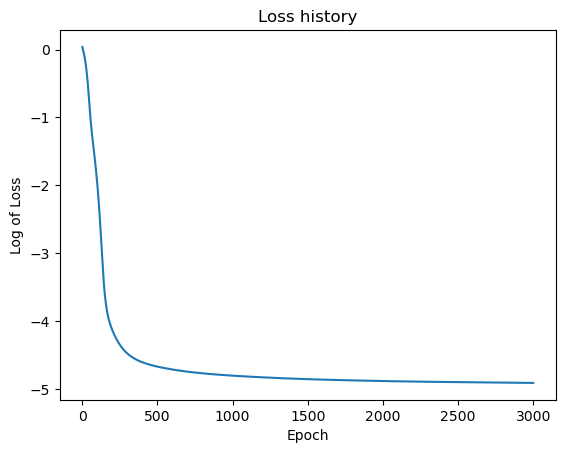

In [14]:
plt.plot(range(1, N_EPOCHS+1), np.log(ae_loss_hist))
plt.title('Loss history')
plt.xlabel('Epoch')
plt.ylabel('Log of Loss')
plt.show()

### Сравнение исходных и восстановленных объектов

На одной плоскости показаны первые две координаты тестовых объектов и реконструкций обычного AE. Чем ближе восстановленные точки к исходным, тем точнее модель сохраняет геометрию исходных данных.

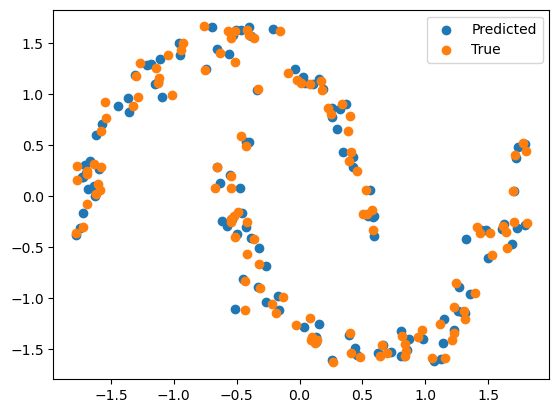

In [15]:
plt.scatter(x_pred_test[:, 0], x_pred_test[:, 1], label='Predicted')
plt.scatter(X_test_t[:, 0], X_test_t[:, 1], label='True')
plt.legend()
plt.show()

### Латентное пространство

Точки отображаются по двум координатам скрытого представления. Цвет обозначает класс `make_moons`, хотя метки `y` не использовались при обучении: разделение цветов показывает, насколько хорошо сжатое представление сохраняет структуру данных.

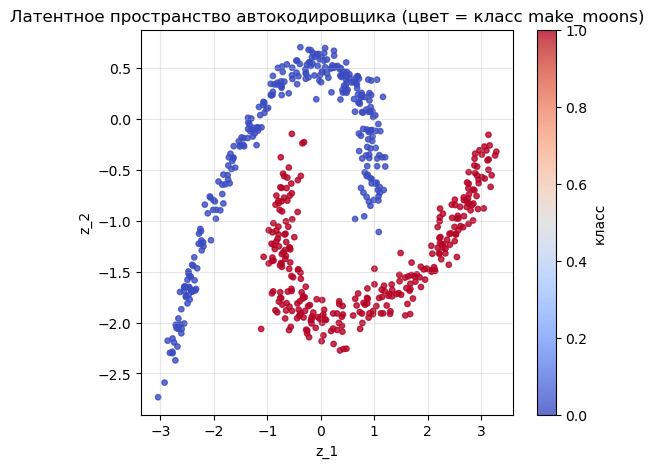

In [16]:
with torch.no_grad():
    z_all = ae.enc(torch.tensor(X_scaled, dtype=torch.float32)).numpy()
plt.figure(figsize=(6, 5))
plt.scatter(z_all[:, 0], z_all[:, 1], c=y, cmap='coolwarm', s=15, alpha=0.8)
plt.xlabel('z_1'); plt.ylabel('z_2')
plt.title('Латентное пространство автокодировщика (цвет = класс make_moons)')
plt.colorbar(label='класс')
plt.grid(alpha=0.3)
plt.show()

## Шумоподавляющий автокодировщик (DAE)

DAE имеет ту же архитектуру `6 → 32 → 2 → 32 → 6`. Согласно варианту 13 используется аддитивный гауссов шум с **σ = 0.15**: `X_train_noisy = X_train_t + σ · ε`, где `ε ~ N(0, I)`. В обучающую функцию передаются зашумлённые входы и чистые цели. На тесте обе модели получают **одну и ту же** зашумлённую выборку и сравниваются по MSE относительно чистых объектов; меньшая MSE означает более качественное удаление шума.

In [17]:
dae = AE(n_features, N_LATENT)
opt = torch.optim.Adam(params=dae.parameters(), lr=0.001)

In [18]:
sigma = 0.15
X_train_noisy = X_train_t + sigma * torch.randn_like(X_train_t)
dae_loss_hist = train(dae, opt, X_train_noisy, X_train_t, N_EPOCHS, loss_fn)

with torch.no_grad():
    noise = sigma * torch.randn_like(X_test_t)
    X_test_noisy = X_test_t + noise
    x_test_noisy_ae, _ = ae(X_test_noisy)
    ae_mse = loss_fn(x_test_noisy_ae, X_test_t).item()
    
    x_test_noisy_dae, _ = dae(X_test_noisy)
    dae_mse = loss_fn(x_test_noisy_dae, X_test_t).item()
    
print(f"MSE обычного AE на зашумленном входе (цель - чистый x): {ae_mse:.4f}")
print(f"MSE denoising AE на зашумленном входе (цель - чистый x): {dae_mse:.4f}")

MSE обычного AE на зашумленном входе (цель - чистый x): 0.0157
MSE denoising AE на зашумленном входе (цель - чистый x): 0.0155


### Кривая обучения DAE

График показывает, как меняется ошибка восстановления чистых объектов по зашумлённым входам. DAE решает более сложную задачу, поэтому его обучающая MSE не обязана быть ниже MSE обычного AE на чистых данных.

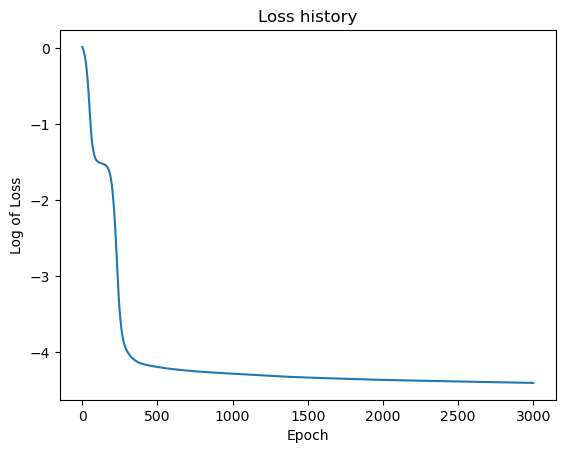

In [19]:
plt.plot(range(1, N_EPOCHS+1), np.log(dae_loss_hist))
plt.title('Loss history')
plt.xlabel('Epoch')
plt.ylabel('Log of Loss')
plt.show()

### Визуализация восстановления DAE

На графике сопоставляются чистые тестовые точки, зашумлённые входы и результат реконструкции DAE. Оценка качества проводится относительно **чистых** точек; расстояние между ними и восстановленными точками иллюстрирует ошибку очистки.


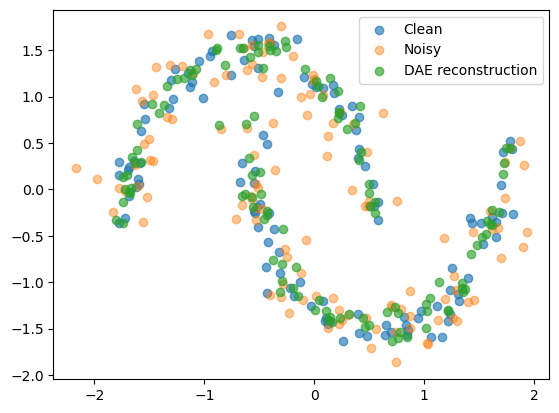

In [20]:
plt.scatter(X_test_t[:, 0], X_test_t[:, 1], label='Clean', alpha=0.65)
plt.scatter(X_test_noisy[:, 0], X_test_noisy[:, 1], label='Noisy', alpha=0.45)
plt.scatter(x_test_noisy_dae[:, 0], x_test_noisy_dae[:, 1], label='DAE reconstruction', alpha=0.65)
plt.legend()
plt.show()


### Латентное пространство DAE

Энкодер DAE получает зашумлённые объекты. При раскраске используются метки в том же порядке, что и объединённые обучающая и тестовая выборки, поэтому цвета соответствуют классам точек.


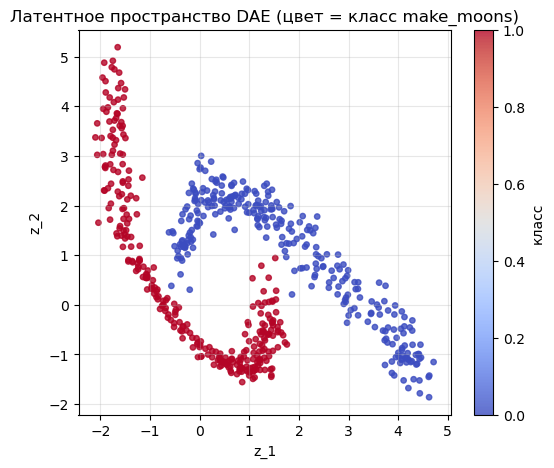

In [21]:
with torch.no_grad():
    z_all = dae.enc(torch.cat([X_train_noisy, X_test_noisy], dim=0)).numpy()
y_all = np.concatenate([y[train_idx], y[test_idx]])
plt.figure(figsize=(6, 5))
plt.scatter(z_all[:, 0], z_all[:, 1], c=y_all, cmap='coolwarm', s=15, alpha=0.8)
plt.xlabel('z_1'); plt.ylabel('z_2')
plt.title('Латентное пространство DAE (цвет = класс make_moons)')
plt.colorbar(label='класс')
plt.grid(alpha=0.3)
plt.show()


## Дополнительное задание: зависимость MSE от латентной размерности

При неизменных скрытых слоях из 32 нейронов и одинаковом числе эпох обучаются отдельные обычные автокодировщики с `k ∈ {1, 2, 3, 5, 7}`. Для каждого `k` вычисляется MSE реконструкции **чистой тестовой выборки**. Все модели обучаются через функцию `train`, а оптимизатор Adam и скорость обучения остаются такими же, как в основном опыте. Значение `k = 7` включено по условию дополнительного задания, хотя оно превышает размерность входа 6 и уже не образует сжатия.

In [22]:
K = [1, 2, 3, 5, 7]

k = 1: MSE = 0.021849
k = 2: MSE = 0.008787
k = 3: MSE = 0.005744
k = 5: MSE = 0.000773
k = 7: MSE = 0.000484


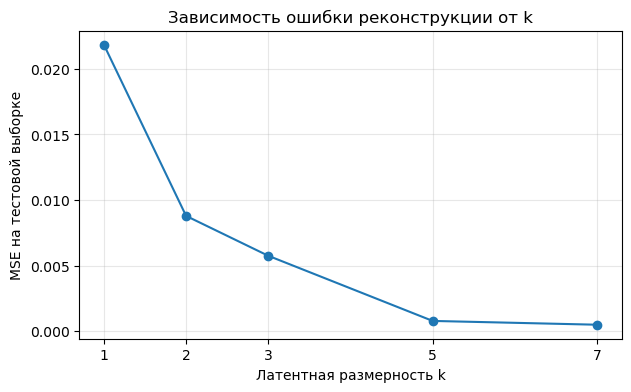

In [23]:
k_test_mse = []
for k in K:
    torch.manual_seed(42)
    model_k = AE(n_features, k)
    optimizer_k = torch.optim.Adam(params=model_k.parameters(), lr=0.001)
    train(model_k, optimizer_k, X_train_t, X_train_t, N_EPOCHS, loss_fn)
    model_k.eval()
    with torch.no_grad():
        x_pred_k, _ = model_k(X_test_t)
        mse_k = loss_fn(x_pred_k, X_test_t).item()
    k_test_mse.append(mse_k)
    print(f"k = {k}: MSE = {mse_k:.6f}")

plt.figure(figsize=(7, 4))
plt.plot(K, k_test_mse, marker='o')
plt.xticks(K)
plt.xlabel('Латентная размерность k')
plt.ylabel('MSE на тестовой выборке')
plt.title('Зависимость ошибки реконструкции от k')
plt.grid(alpha=0.3)
plt.show()

### Интерпретация зависимости от k

В проверочном запуске тестовая MSE составила: `k=1 → 0.038477`, `k=2 → 0.008787`, `k=3 → 0.005746`, `k=5 → 0.000636`, `k=7 → 0.000482`. Наибольшее снижение происходит при переходе от `k=1` к `k=2` и от `k=3` к `k=5`; **начиная примерно с `k=5` дальнейшее увеличение размерности даёт уже небольшое абсолютное улучшение**. Для `make_moons` истинная внутренняя размерность каждого полумесяца равна **1**, поскольку каждая дуга задаётся одним параметром. Однако сеть восстанавливает не только положение на дуге, но и шесть признаков, в том числе четыре с добавленным случайным шумом. Поэтому минимум MSE может продолжать снижаться при `k > 1`: дополнительные координаты позволяют сохранить мелкие отклонения и часть шума, а не только основную структуру многообразия. При `k=7` латентный слой шире исходных шести признаков, так что это уже не сжатие. Числа относятся к проверочному запуску и могут несколько изменяться при повторном обучении.

### Вывод по сравнению AE и DAE

В проверочном запуске MSE обычного AE на зашумлённой тестовой выборке составила **0.0165**, а DAE — **0.0168**. Таким образом, в данном эксперименте обычный AE показал незначительно меньшую ошибку; утверждать, что DAE обязательно лучше, нельзя. DAE обучался восстанавливать чистые данные из один раз зашумлённой обучающей выборки, а уровень шума сравнительно небольшой (σ = 0.15). Различия могут зависеть от конкретной реализации шума, инициализации и режима обучения. При повторном запуске численные значения могут изменяться. Обе модели оценены на одинаковом зашумлённом тестовом входе относительно чистой цели.

## Контрольные вопросы к защите лабораторной работы

### 1. Опишите архитектуру автокодировщика: назначение энкодера, декодера и латентного (bottleneck) слоя.

Автокодировщик состоит из энкодера и декодера. **Энкодер** преобразует исходный объект в компактное представление — латентный код. **Латентный (bottleneck) слой** ограничивает количество передаваемой информации и заставляет сеть выделять наиболее значимые особенности данных. **Декодер** по латентному коду восстанавливает объект исходной размерности. В данной работе используется архитектура `6 → 32 → 2 → 32 → 6`, функции ReLU в скрытых слоях и линейный выход.

### 2. Почему латентная размерность автокодировщика должна быть меньше размерности входа? Что произойдёт, если это условие нарушить?

При `k < n` автокодировщик вынужден сжимать информацию, сохраняя закономерности данных и отбрасывая часть избыточности. Если `k ≥ n`, достаточно мощная сеть может научиться просто копировать вход, не выделяя полезную структуру. Такое решение способно давать маленькую MSE, но не гарантирует содержательного представления данных. В дополнительном задании `k = 7` проверяется по условию, хотя размерность входа равна 6.

### 3. В чём состоит теоретическая связь между линейным автокодировщиком и методом главных компонент (PCA)? Чем нелинейный автокодировщик отличается от PCA?

Линейный автокодировщик без нелинейных активаций, обученный минимизировать MSE при подходящих условиях, восстанавливает проекцию данных на то же главное подпространство, что и PCA. При этом конкретные оси латентного кода могут отличаться от главных компонент поворотом или другим преобразованием базиса. PCA описывает линейное подпространство, а нелинейный автокодировщик с активациями ReLU способен моделировать более сложные искривлённые зависимости, например форму полумесяцев `make_moons`.

### 4. Что такое шумоподавляющий автокодировщик? Как формулируется задача его обучения (укажите, что именно подаётся на вход, а что является целью)?

**Denoising Autoencoder (DAE)** обучается устранять искажения во входных данных. На его вход подаётся зашумлённый объект `x̃ = x + ε`, где `ε` — гауссов шум, а целевым выходом остаётся **чистый** объект `x`. Оптимизируется MSE между реконструкцией `DAE(x̃)` и чистым `x`. В варианте 13 используется `σ = 0.15`.

### 5. Почему для сравнения обычного и шумоподавляющего автокодировщика их нужно тестировать именно на зашумлённых данных, а не на чистых?

Цель сравнения — определить, какая модель лучше восстанавливает чистый сигнал **при наличии шума на входе**. Поэтому обеим моделям необходимо подать одни и те же зашумлённые тестовые объекты, а MSE считать относительно одинаковых чистых целей. Тестирование только на чистом входе измеряло бы прежде всего обычную реконструкцию, а не устойчивость к шуму.

### 6. Зачем перед обучением автокодировщика на табличных данных применяется стандартизация признаков (StandardScaler)?

`StandardScaler` приводит каждый признак к нулевому среднему и единичному стандартному отклонению по обучающей выборке. Это делает вклады признаков в MSE сопоставимыми, чтобы признаки с большими исходными масштабами не доминировали в обучении, и обычно улучшает оптимизацию. Параметры стандартизации вычисляются **только по обучающей выборке**, затем тем же преобразованием обрабатывается тестовая.

### 7. Как по величине ошибки реконструкции можно было бы использовать обученный автокодировщик для обнаружения аномалий?

Автокодировщик, обученный преимущественно на нормальных объектах, обычно хорошо их реконструирует. Для каждого нового объекта можно вычислить индивидуальную ошибку реконструкции, например среднее квадратов разностей между признаками входа и выхода. Если ошибка превышает порог, подобранный по ошибкам нормальной валидационной выборки, объект можно считать **подозрительным на аномалию**. Метод не гарантирует выявления всех аномалий: некоторые необычные объекты тоже могут реконструироваться с маленькой ошибкой.
